Found 914 images belonging to 2 classes.
Found 216 images belonging to 2 classes.
🔵 Fase 1: Transfer Learning
Epoch 1/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.8775 - loss: 0.2546 - val_accuracy: 0.9769 - val_loss: 0.0724
Epoch 2/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 70s 2s/step - accuracy: 0.9706 - loss: 0.0773 - val_accuracy: 0.9676 - val_loss: 0.0662
Epoch 3/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.9787 - loss: 0.0530 - val_accuracy: 0.9398 - val_loss: 0.1663
Epoch 4/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 76s 3s/step - accuracy: 0.9856 - loss: 0.0358 - val_accuracy: 0.9722 - val_loss: 0.0925
Epoch 5/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 76s 3s/step - accuracy: 0.9908 - loss: 0.0290 - val_accuracy: 0.9722 - val_loss: 0.0796
🟢 Fase 2: Fine Tuning
Epoch 1/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 99s 3s/step - accuracy: 0.9290 - loss: 0.1730 - val_accuracy: 0.9676 - val_loss: 0.1021
Epoch 2/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 73s 3s/step - accuracy: 0.9691 - loss: 0.0834 - val_accuracy: 0.9676 - val_loss: 

✅ Modelo guardado como modelo_gatos_perros.h5
📊 Matriz de Confusión
7/7 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step


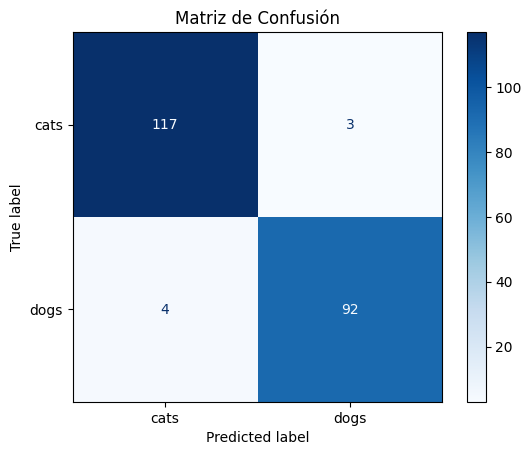

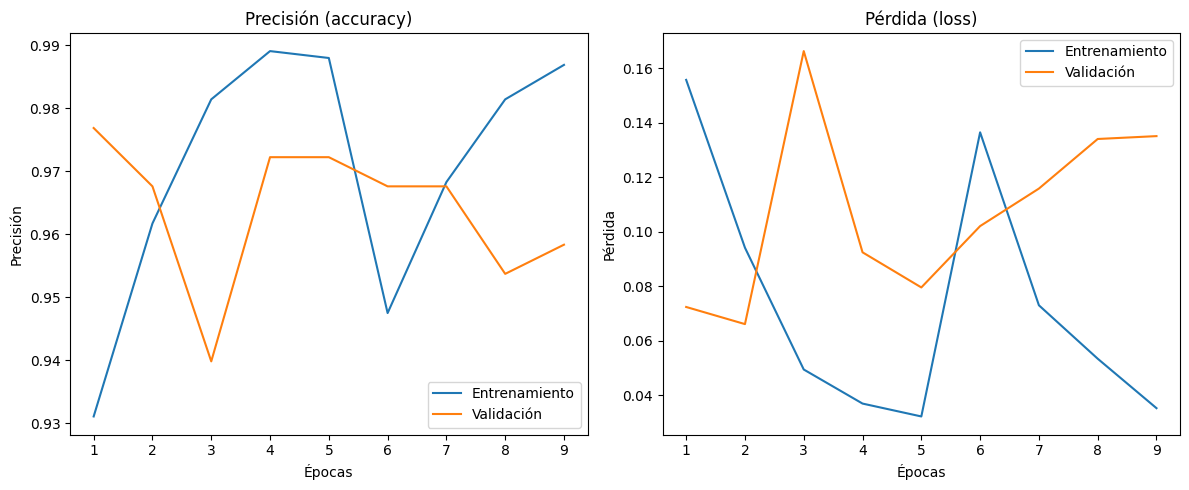

In [5]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# --- PARÁMETROS ---
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS_TL = 5  # Transfer Learning
EPOCHS_FT = 5  # Fine-Tuning
LR_TL = 1e-3
LR_FT = 1e-4

# --- DATA AUGMENTATION ---
train_gen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

val_gen = ImageDataGenerator(rescale=1./255)

train_data = train_gen.flow_from_directory(
    '/content/drive/MyDrive/practicasMachineL/DEEPLEARNING/GATOSPERROS/DATASET/dogscats/train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

val_data = val_gen.flow_from_directory(
    '/content/drive/MyDrive/practicasMachineL/DEEPLEARNING/GATOSPERROS/DATASET/dogscats/valid',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# --- TRANSFER LEARNING ---
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
output = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=output)
model.compile(optimizer=Adam(learning_rate=LR_TL),
              loss='binary_crossentropy',
              metrics=['accuracy'])

early_stop = EarlyStopping(patience=3, restore_best_weights=True)

print("🔵 Fase 1: Transfer Learning")
history_tl = model.fit(train_data, validation_data=val_data, epochs=EPOCHS_TL, callbacks=[early_stop])

# --- FINE-TUNING ---
print("🟢 Fase 2: Fine Tuning")
base_model.trainable = True
for layer in base_model.layers[:-20]:  # solo últimas 20 capas se entrenan
    layer.trainable = False

model.compile(optimizer=Adam(learning_rate=LR_FT),
              loss='binary_crossentropy',
              metrics=['accuracy'])

history_ft = model.fit(train_data, validation_data=val_data, epochs=EPOCHS_FT, callbacks=[early_stop])

# --- GUARDAR MODELO ---
model.save("/content/drive/MyDrive/practicasMachineL/DEEPLEARNING/GATOSPERROS/DATASET/modelo_gatos_perros2.h5")
print("✅ Modelo guardado como modelo_gatos_perros.h5")

# --- MATRIZ DE CONFUSIÓN ---
print("📊 Matriz de Confusión")
val_data.reset()
y_true = val_data.classes
y_pred = model.predict(val_data)
y_pred_classes = (y_pred > 0.5).astype(int).reshape(-1)

cm = confusion_matrix(y_true, y_pred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=val_data.class_indices)
disp.plot(cmap='Blues')
plt.title("Matriz de Confusión")
plt.show()

# --- GRÁFICAS DE ACCURACY Y LOSS ---
def plot_metrics(history1, history2):
    acc = history1.history['accuracy'] + history2.history['accuracy']
    val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
    loss = history1.history['loss'] + history2.history['loss']
    val_loss = history1.history['val_loss'] + history2.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, label='Entrenamiento')
    plt.plot(epochs, val_acc, label='Validación')
    plt.title('Precisión (accuracy)')
    plt.xlabel('Épocas')
    plt.ylabel('Precisión')
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label='Entrenamiento')
    plt.plot(epochs, val_loss, label='Validación')
    plt.title('Pérdida (loss)')
    plt.xlabel('Épocas')
    plt.ylabel('Pérdida')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_metrics(history_tl, history_ft)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import numpy as np

# ✅ Cargar el modelo previamente entrenado
modelo = tf.keras.models.load_model('/content/drive/MyDrive/practicasMachineL/DEEPLEARNING/GATOSPERROS/DATASET/modelo_gatos_perros2.h5')

# ✅ Definir etiquetas según el orden de las carpetas en el entrenamiento
clases = ['gatos', 'perros']  # Asegúrate de que esto coincida con las carpetas originales

# ✅ Cargar y preprocesar una imagen para predecir
def predecir_imagen(ruta_imagen):
    img = image.load_img(ruta_imagen, target_size=(224, 224))  # Usa el mismo tamaño usado en el entrenamiento
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    pred = modelo.predict(img_array)

    if pred.shape[1] == 1:  # Si usaste class_mode='binary'
        clase_predicha = clases[int(pred[0][0] > 0.5)]
        confianza = pred[0][0] if pred[0][0] > 0.5 else 1 - pred[0][0]
    else:  # Si usaste class_mode='categorical'
        clase_predicha = clases[np.argmax(pred)]
        confianza = np.max(pred)

    print(f'Predicción: {clase_predicha} ({confianza*100:.2f}% de confianza)')

# ✅ Usar la función
ruta = '/content/drive/MyDrive/practicasMachineL/DEEPLEARNING/GATOSPERROS/DATASET/dogscats/test/3.jpg'
predecir_imagen(ruta)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicción: perros (100.00% de confianza)


NameError: name 'historia' is not defined

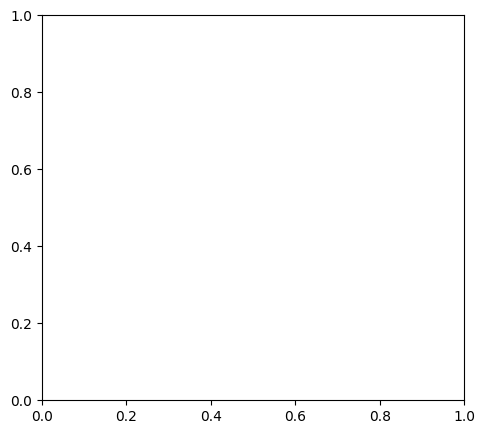

In [4]:
# ✅ 9. VISUALIZAR RESULTADOS
import os
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))

# Precisión
plt.subplot(1, 2, 1)
plt.plot(historia.history['accuracy'], label='Entrenamiento')
plt.plot(historia.history['val_accuracy'], label='Validación')
plt.title('Precisión')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()

# Pérdida
plt.subplot(1, 2, 2)
plt.plot(historia.history['loss'], label='Entrenamiento')
plt.plot(historia.history['val_loss'], label='Validación')
plt.title('Pérdida')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()

plt.tight_layout()
plt.show()